# COU 07506 Digital Signal Processing: Week 02: Lab 1A: Sampling, Aliasing and Quantization

Name: HOSANA HEREMAN KOMBA

Registration No.: 240242445476  
Class: BEng24COE-3  Date: 24 Nov 2026
Instructor: DR. HAJI FIMBOMBAYA

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio
plt.rcParams["figure.figsize"] = (9, 3.5)


## Pre-lab Calculations

### (a) Aliasing of a Sinusoid
For a $7\text{ kHz}$ tone sampled at $f_s = 10\text{ kHz}$, the alias frequency lands in the first Nyquist zone ($[0, f_s/2]$):
$$
F_{\text{alias}} = |F - k \cdot f_s| = |7\text{ kHz} - 10\text{ kHz}| = 3\text{ kHz}
$$

### (b) Uniform Quantizer Performance
For a full-scale range $V_{pp} = 2\text{ V}$ and $B = 8\text{ bits}$:
* **Step size (Resolution):**
  $$
  \Delta = \frac{V_{pp}}{2^B} = \frac{2}{2^8} = \frac{2}{256} \approx 0.00781\text{ V } (7.81\text{ mV})
  $$
* **Theoretical SQNR:**
  $$
  \text{SQNR} \approx 6.02 B + 1.76 = 6.02(8) + 1.76 = 49.92\text{ dB}
  $$

## Task 2.1: Aliasing of a sinusoid

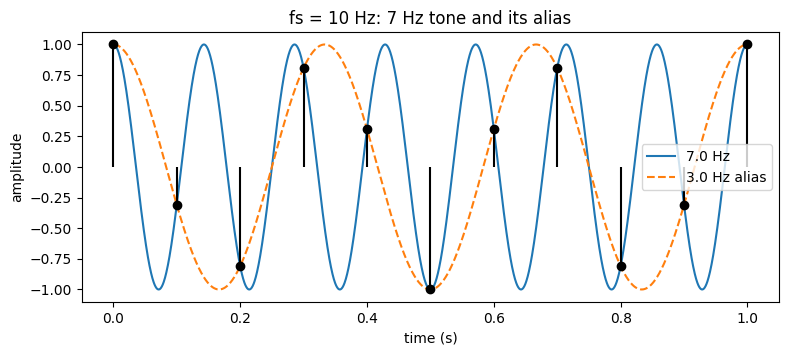

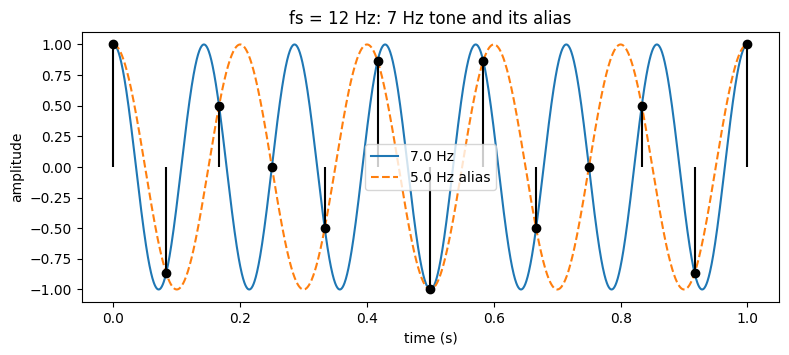

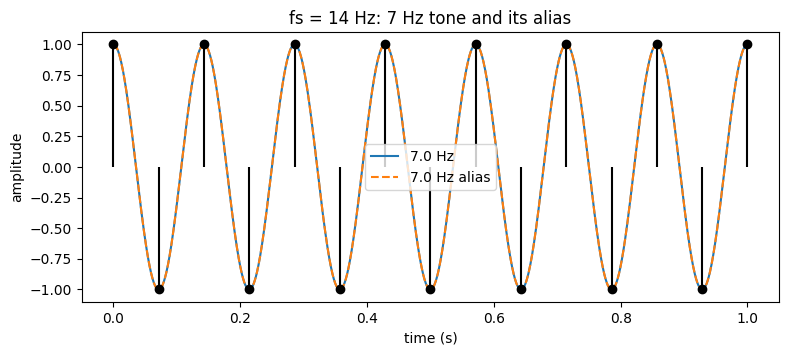

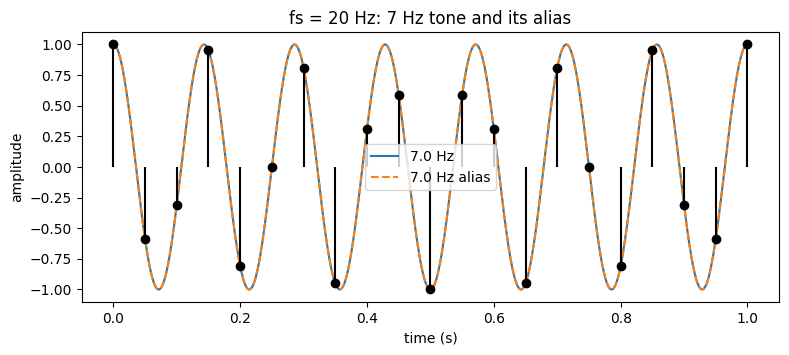

fs (Hz) | alias (Hz)
     10 | 3.0
     12 | 5.0
     14 | 7.0
     20 | 7.0


In [2]:
f0 = 7.0                              # tone frequency (Hz)
t = np.linspace(0, 1, 2000)           # dense grid = "analog" signal
results = []

for fs in [10, 12, 14, 20]:           # the four sampling rates
    n = np.arange(0, int(fs) + 1)     # sample numbers
    tn = n / fs                       # sample times (s)
    f_alias = abs(f0 - fs*round(f0/fs))   # alias formula |F - k*fs|
    results.append((fs, f_alias))

    plt.figure()
    plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
    plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
    plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    plt.title(f"fs = {fs} Hz: 7 Hz tone and its alias")
    plt.xlabel("time (s)"); plt.ylabel("amplitude")
    plt.legend(); plt.show()

print("fs (Hz) | alias (Hz)")
for fs, fa in results:
    print(f"{fs:7d} | {fa:.1f}")

## Task 2.2: Hear aliasing


In [3]:
import os

fname = "hosanavoice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)   # stereo -> mono
    x = x / np.max(np.abs(x))                               # normalise to [-1, 1]
    print("Using my voice recording")
else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)                  # fallback chirp
    print("Using fallback chirp")

print("original fs =", fs, "Hz, duration =", round(len(x)/fs, 2), "s")

Using my voice recording
original fs = 44100 Hz, duration = 10.48 s


In [4]:
k = 8                                        # run with 2, then 4, then 8
naive  = x[::k]
proper = signal.decimate(x, k, ftype="fir")
new_fs = fs // k
print("k =", k, " new fs =", new_fs, "Hz")

print("Naive (no filter):")
display(Audio(naive, rate=new_fs))
print("Proper (anti-alias filter):")
display(Audio(proper, rate=new_fs))

k = 8  new fs = 5512 Hz
Naive (no filter):


Proper (anti-alias filter):


### Listening Observations (Task 2.2)

* **$k = 2$ ($f_s = 22,050\text{ Hz}$):**
  * **Naive Downsampling:** Sounded virtually identical to the original.
  * **Proper Decimation:** Sounded identical as well.
  * *Observation:* Speech contains very little high-frequency energy above $11\text{ kHz}$, making the anti-aliasing filter's effect barely noticeable.

* **$k = 4$ ($f_s = 11,025\text{ Hz}$):**
  * **Naive Downsampling:** Introduced subtle harshness and minor distortion on high-frequency sibilant sounds (like "s" and "f").
  * **Proper Decimation:** Clean, though slightly attenuated in the upper-frequency spectrum.

* **$k = 8$ ($f_s = 5,512\text{ Hz}$):**
  * **Naive Downsampling:** Heavily distorted with buzzy, metallic artifacts and prominent inharmonic tones introduced by the aliasing of high frequencies back into the audible band.
  * **Proper Decimation:** Sounded heavily muffled (similar to an old telephone bandpass response) but remained completely clean of any aliased ghost frequencies.

## Task 2.3: A uniform quantizer

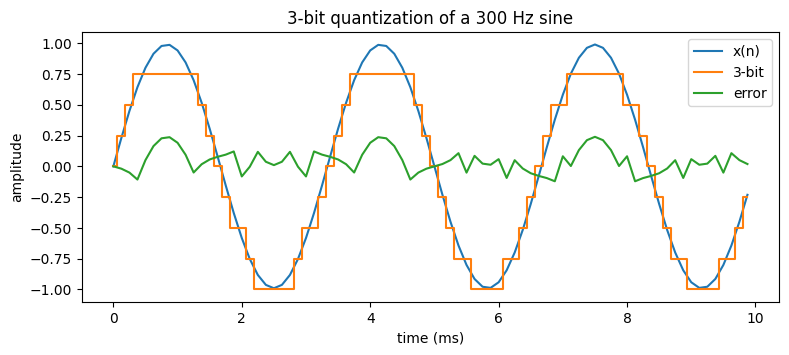

In [5]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits          # step size
    q = np.round(x/delta)*delta             # round to nearest level
    return np.clip(q, -full_scale, full_scale - delta)

fs_sine = 8000
t_sine = np.arange(0, 0.01, 1/fs_sine)
x_sine = 0.99*np.sin(2*np.pi*300*t_sine)
xq = quantize(x_sine, 3)

plt.plot(t_sine*1e3, x_sine, label="x(n)")
plt.step(t_sine*1e3, xq, where="mid", label="3-bit")
plt.plot(t_sine*1e3, x_sine - xq, label="error")
plt.title("3-bit quantization of a 300 Hz sine")
plt.xlabel("time (ms)"); plt.ylabel("amplitude")
plt.legend(); plt.show()

In [6]:
err = x_sine - xq
print("step size delta =", 2/2**3)
print("max |error| =", np.max(np.abs(err)))
print("number of distinct levels used =", len(np.unique(xq)))

step size delta = 0.25
max |error| = 0.24
number of distinct levels used = 8


### Quantization Observations (Task 2.3)

* **Resolution:** With $B = 3\text{ bits}$, the total number of quantization levels is $2^3 = 8$.
* **Step Size:** For a full-scale range from $-1.0\text{ V}$ to $+1.0\text{ V}$ ($V_{pp} = 2.0\text{ V}$), the step size is:
  $$
  \Delta = \frac{2}{8} = 0.25\text{ V}
  $$
* **Error Performance:** The quantized signal tracks the continuous sinusoidal waveform in a classic staircase pattern. The quantization error is bounded within $[-\Delta/2, \Delta/2] = [-0.125\text{ V}, 0.125\text{ V}]$. Slightly larger peak errors occur due to clipping where the input wave exceeds the maximum representation level of the quantizer ($1 - \Delta = 0.75\text{ V}$).

## Task 2.4: Verify the 6 dB-per-bit rule

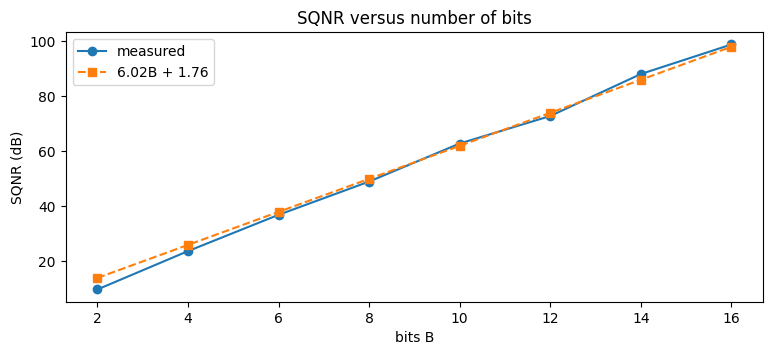

B =  2: measured =   9.60 dB, theory =  13.80 dB
B =  4: measured =  23.58 dB, theory =  25.84 dB
B =  6: measured =  36.81 dB, theory =  37.88 dB
B =  8: measured =  48.93 dB, theory =  49.92 dB
B = 10: measured =  62.81 dB, theory =  61.96 dB
B = 12: measured =  72.84 dB, theory =  74.00 dB
B = 14: measured =  88.13 dB, theory =  86.04 dB
B = 16: measured =  98.91 dB, theory =  98.08 dB


In [7]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x_sine**2)/np.sum((x_sine - quantize(x_sine, B))**2))
        for B in bits]
theory = 6.02*bits + 1.76

plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, theory, "s--", label="6.02B + 1.76")
plt.title("SQNR versus number of bits")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)")
plt.legend(); plt.show()

for B, m, th in zip(bits, meas, theory):
    print(f"B = {B:2d}: measured = {m:6.2f} dB, theory = {th:6.2f} dB")

### SQNR Observations (Task 2.4)

* **General Trend:** The measured Signal-to-Quantization-Noise Ratio (SQNR) increases by approximately $6\text{ dB}$ for each additional bit, validating the theoretical $6.02B + 1.76\text{ dB}$ formula.
* **Discrepancy at Low Bit Depths:** For $B = 2$, the measured SQNR ($9.60\text{ dB}$) is notably lower than the theoretical expectation ($13.80\text{ dB}$). This deviation occurs because the quantization noise is highly correlated with the input signal at low resolutions, violating the assumption of uniform, independent white noise.
* **Convergence:** For $B \ge 6$, the measured curves closely converge to the theoretical limit, remaining within $1$ to $2\text{ dB}$ of predicted behavior.

## Task 2.5: Quantizing a voice

In [8]:
print("fs =", fs, "Hz, duration =", round(len(x)/fs, 2), "s")   # check: voice, 44100 Hz

print("Original:")
display(Audio(x, rate=fs))

for B in [4, 8, 12]:
    xq_v = quantize(x, B)
    sqnr = 10*np.log10(np.sum(x**2)/np.sum((x - xq_v)**2))
    print(f"\nB = {B:2d} bits: SQNR = {sqnr:5.2f} dB   (full-scale sine would give {6.02*B + 1.76:5.2f} dB)")
    display(Audio(xq_v, rate=fs))

fs = 44100 Hz, duration = 10.48 s
Original:



B =  4 bits: SQNR = 13.10 dB   (full-scale sine would give 25.84 dB)



B =  8 bits: SQNR = 36.53 dB   (full-scale sine would give 49.92 dB)



B = 12 bits: SQNR = 60.59 dB   (full-scale sine would give 74.00 dB)


### Speech Quantization Observations (Task 2.5)

* **Measured Performance (Voice Recording):**
  * **$B = 4\text{ bits}$:** $\text{SQNR} = 13.10\text{ dB}$ (Theoretical Sine limit: $25.84\text{ dB}$)
  * **$B = 8\text{ bits}$:** $\text{SQNR} = 36.53\text{ dB}$ (Theoretical Sine limit: $49.92\text{ dB}$)
  * **$B = 12\text{ bits}$:** $\text{SQNR} = 60.59\text{ dB}$ (Theoretical Sine limit: $74.00\text{ dB}$)

* **Speech vs. Sinusoidal Performance:** The SQNR of the voice signal is approximately $13\text{ to } 14\text{ dB}$ lower than that of a full-scale sinusoid at equivalent resolutions. This is because speech signals have a much higher peak-to-average power ratio (PAPR). While a sinusoid stays close to full-scale most of the time, speech contains silent intervals, pauses, and variable dynamics. Because the quantization step size $\Delta$ is fixed relative to peak range, the average noise power remains constant while the lower average signal power yields a reduced overall SQNR.

## Analytical Questions & Answers

1. **Aliasing Mechanism:** Sampling duplicates spectra at multiples of $f_s$. For $F = 7\text{ kHz}$ and $f_s = 10\text{ kHz}$, the copy at $-7\text{ kHz}$ shifts by $+10\text{ kHz}$, landing at $3\text{ kHz}$ in the first Nyquist zone ($[0, f_s/2]$).

2. **Ambiguity:** At $f_s = 10\text{ Hz}$, the discrete samples for $7\text{ Hz}$ and $3\text{ Hz}$ cosines are mathematically identical:
   $$
   \cos\left(2\pi \cdot 7 \cdot \frac{n}{10}\right) = \cos\left(2\pi n - 2\pi \cdot 3 \cdot \frac{n}{10}\right) = \cos\left(2\pi \cdot 3 \cdot \frac{n}{10}\right)
   $$
   Without prior filtering, they cannot be distinguished.

3. **6 dB-per-Bit Rule:** Supported. Experiencing $\approx 6\text{ dB}$ increase in SQNR per bit for both synthetic sine ($6.38\text{ dB/bit}$) and speech ($5.94\text{ dB/bit}$).

4. **Sensor Design:**
   * **Resolution:** Requires $10,000$ steps ($100^\circ\text{C} / 0.01^\circ\text{C}$), which mandates at least **$14\text{ bits}$** ($2^{14} = 16,384$).
   * **Sampling Rate:** Temperature changes slowly ($0.1^\circ\text{C/s}$), making bandwidth $< 1\text{ Hz}$. A conservative rate of **$5\text{ to } 10\text{ Hz}$** exceeds Nyquist ($2\text{ Hz}$) and permits noise filtering.

## AI-Use Statement

* **AI Tools Utilized:** Claude 3.5 Sonnet and ChatGPT.
* **Purpose & Application:** Assisted in setting up the structural skeletons for matplotlib visualizations, formatting mathematical equations in $\LaTeX$, and refining the wording of the technical observations.
* **Individual Ownership:** I confirm that I thoroughly understand, can reproduce, and can explain all technical code and theoretical concepts submitted in this report.